## Install Dependencies

In [19]:
#!pip install librosa numpy pandas scipy

## Load Audio Files
Load the wav files for further processing.

In [20]:
import os
import librosa
import numpy as np

DATASET_PATH = "Dataset_wav/"

def load_audio_files(dataset_path):
    data = []
    labels = []

    for label in os.listdir(dataset_path): #we use our folder names as labels as we structures the dataset folder that way
        label_path = os.path.join(dataset_path, label) #join the folder name (label) and dataset path

        for file in os.listdir(label_path):
            if file.endswith(".wav"): 
                file_path = f"{label_path}/{file}" #using / here as os.path.join was using backslash for some reason
                audio, sr = librosa.load(file_path, sr=None)  
                data.append(audio)
                labels.append(label)

    return data, labels

audio_data, audio_labels = load_audio_files(DATASET_PATH)
print(f"Loaded {len(audio_data)} samples.")


Loaded 82 samples.


In [21]:
# Sample rate
sample_rate = 44100
cutoff_samples = sample_rate  # Taking off one second since it was pure background noise for most of the samples.

cut_audio_data = []

for audio in audio_data:
    cut_audio = audio[cutoff_samples:]  
    cut_audio_data.append(cut_audio)

audio_data = cut_audio_data # Changing the audio data to the one that has been trimmed. 
print(f"Trimmed first second from {len(audio_data)} audio samples.")


Trimmed first second from 82 audio samples.


In [22]:
from scipy.signal import butter, lfilter

def butter_bandpass(lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_bandpass_filter(data, lowcut, highcut, fs):
    b, a = butter_bandpass(lowcut, highcut, fs)
    return lfilter(b, a, data)


In [23]:
# Here we are doing the flitering with our cut off parameters between 300-3000 Hz
lowcut = 300    
highcut = 3000  
sample_rate = 44100      

filtered_audio_data = []

for audio, label in zip(audio_data, audio_labels):
    if label != "Oil": # Applying the fliter to only beer and wine because for oil the background and pouring noises mixed in too much to the point where it was hurting the accuracy. 
        filtered = apply_bandpass_filter(audio, lowcut, highcut, sample_rate)
    else:
        filtered = audio  
    filtered_audio_data.append(filtered)

print(f"Processed {len(filtered_audio_data)} audio samples.")

raw_audio_data = audio_data # Keeping the raw audio for comparison purposes
audio_data = filtered_audio_data


Processed 82 audio samples.


In [24]:
def segment_audio(audio, sr, window_size, overlap): # Segmenting so it gets sample of the audio every 2 seconds with an overlap of 1 second.
    segments = []
    samples_per_window = int(window_size * sr)
    step_size = int(samples_per_window * (1 - overlap))

    for start in range(0, len(audio) - samples_per_window + 1, step_size):
        end = start + samples_per_window
        segment = audio[start:end]
        segments.append(segment)

    return segments


In [25]:
segmented_audio = []
segmented_labels = []

window_size = 2.0  # Setting the parameters here
overlap = 0.5

for audio, label in zip(audio_data, audio_labels):
    sample_rate = 44100  # After earlier conversion the WAV files are at 44100Hz sampling rate
    segments = segment_audio(audio, sample_rate, window_size, overlap)

    for segment in segments:
        segmented_audio.append(segment)
        segmented_labels.append(label)

print(f"Total segments created: {len(segmented_audio)}") # Checking how many segments were created
print(f"Example segment shape: {segmented_audio[0].shape}")

Total segments created: 308
Example segment shape: (88200,)


In [26]:
def extract_features(segment, sr):
    mfccs = librosa.feature.mfcc(y=segment, sr=sr, n_mfcc=13) # MFCCs
    mfccs_mean = np.mean(mfccs, axis=1)

    centroid = np.mean(librosa.feature.spectral_centroid(y=segment, sr=sr)) # Spectral centroid

    bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=segment, sr=sr))  # Spectral bandwidth

    contrast = np.mean(librosa.feature.spectral_contrast(y=segment, sr=sr))  # Spectral contrast

    zcr = np.mean(librosa.feature.zero_crossing_rate(y=segment))  # Zero crossing rate

    features = np.hstack([mfccs_mean, centroid, bandwidth, contrast, zcr]) # Putting all features into one array
    return features


In [27]:
all_features = []
all_labels = []

sample_rate = 44100  # Same sample rate 

for segment, label in zip(segmented_audio, segmented_labels):
    features = extract_features(segment, sample_rate) # Extracting the features
    all_features.append(features)
    all_labels.append(label)

all_features = np.array(all_features)
all_labels = np.array(all_labels)

print("Feature shape:", all_features.shape)
print("Labels shape:", all_labels.shape)


Feature shape: (308, 17)
Labels shape: (308,)


In [28]:
import pandas as pd

feature_columns = [f"mfcc_{i+1}" for i in range(13)] + ["centroid", "bandwidth", "contrast", "zcr"]

df = pd.DataFrame(all_features, columns=feature_columns)
df['label'] = all_labels

df.to_csv("liquid_audio_features_filtered.csv", index=False) # Saving the dataset for model training within a csv file
print("Saved")


Saved


## Plots 
Plots for the report

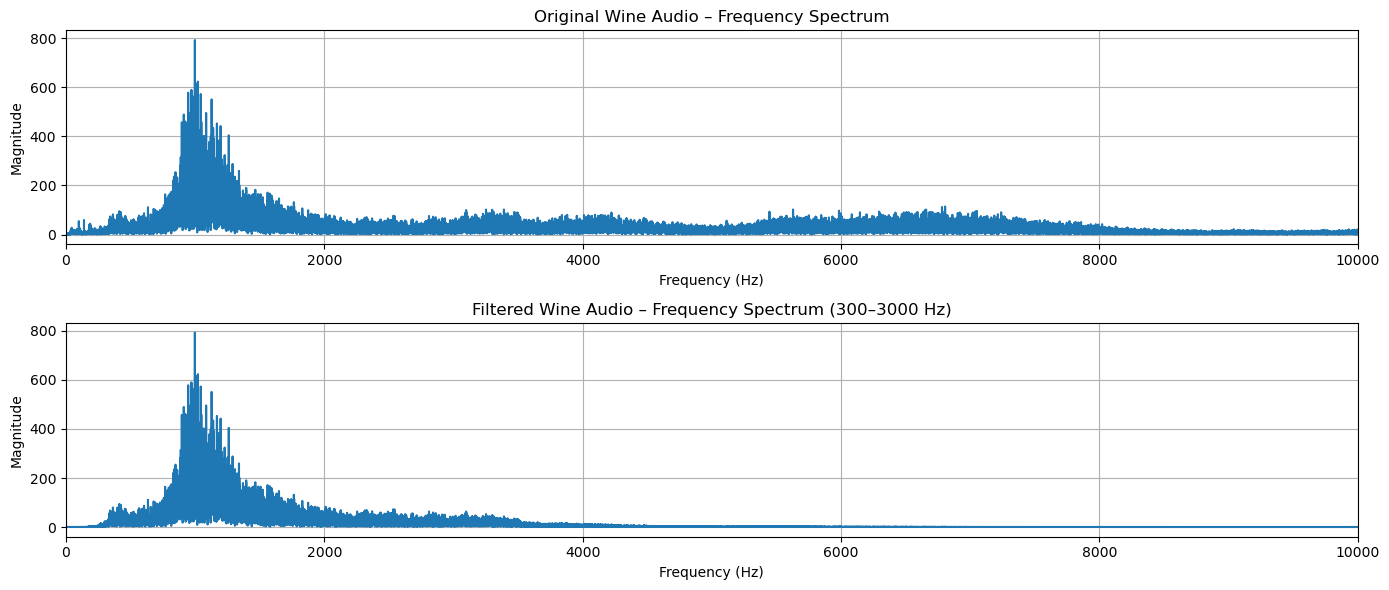

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, sr, title=""):
    N = len(signal)
    yf = fft(signal)
    xf = fftfreq(N, 1 / sr)

    # Keep only positive frequencies
    idx = np.where(xf >= 0)
    xf = xf[idx]
    yf = np.abs(yf[idx])

    plt.plot(xf, yf)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.grid(True)
    plt.xlim(0, 10000)  # Adjust depending on what you want to see

# === 2. Get Wine sample ===
wine_index = audio_labels.index("Wine")
sample_rate = 44100

raw_wine = raw_audio_data[wine_index]
filtered_wine = audio_data[wine_index]

# Optional: Just analyze first 4 seconds
raw_cut = raw_wine[:4 * sample_rate]
filtered_cut = filtered_wine[:4 * sample_rate]

# === 3. Plot frequency spectra ===
plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plot_frequency_spectrum(raw_cut, sample_rate, "Original Wine Audio – Frequency Spectrum")

plt.subplot(2, 1, 2)
plot_frequency_spectrum(filtered_cut, sample_rate, "Filtered Wine Audio – Frequency Spectrum (300–3000 Hz)")

plt.tight_layout()
plt.show()


## Violin Plot of Key Features by Label

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the actual feature dataset
df = pd.read_csv("liquid_audio_features_filtered.csv")

# Set plot style
sns.set(style="whitegrid")

# Create violin plots for key features
plt.figure(figsize=(18, 5))

# Plot 1: Spectral Centroid
plt.subplot(1, 3, 1)
sns.violinplot(data=df, x="label", y="centroid")
plt.title("Spectral Centroid by Liquid")
plt.ylabel("Centroid (Hz)")
plt.xlabel("Liquid")

# Plot 2: Zero Crossing Rate
plt.subplot(1, 3, 2)
sns.violinplot(data=df, x="label", y="zcr")
plt.title("Zero Crossing Rate by Liquid")
plt.ylabel("ZCR")
plt.xlabel("Liquid")

# Plot 3: Spectral Contrast
plt.subplot(1, 3, 3)
sns.violinplot(data=df, x="label", y="contrast")
plt.title("Spectral Contrast by Liquid")
plt.ylabel("Contrast")
plt.xlabel("Liquid")

plt.tight_layout()
plt.show()